In [1]:
import jax_sn

In [ ]:
%load_ext autoreload
%autoreload 2
import jax.numpy as jnp
import jax_sn

import jax_sbgeom as jsb
import jax
import matplotlib.pyplot as plt
import numpy as onp
import equinox as eqx
jax.config.update("jax_enable_x64", True)
from jax_sbgeom.flux_surfaces import FluxSurfaceNormalExtendedNoPhi, ToroidalExtent, FluxSurface
from jax_sn.tools.memory_analysis import _filter_jit_f_to_memory
vmec_file = ["/home/tbogaarts/stellarator_paper/base_data/vmecs/helias5_vmec.nc4"][0]
fs_base = FluxSurfaceNormalExtendedNoPhi.from_hdf5(vmec_file)
from functools import partial
import pyvista as pv
from jax_sbgeom.jax_utils import mesh_to_pyvista_mesh
import lineax as lx
from jax_sn.operators.multi_group_operator import MultiGroupLowerTriangularBlockSolver
from typing import Tuple, Callable
from dataclasses import dataclass


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
from breeding_blanket_setup import _get_bb_args, _setup_bb_args

In [ ]:
bb_args_1D = _get_bb_args(1,6)
MGOP, source_total, solution_domain = _setup_bb_args(*bb_args_1D)

In [ ]:
from jax_sn.operators.multi_group_operator import MultiGroupLowerTriangularBlockSolver, MultiGroupOperator
from jax_sn.parametrisation.base_parametrisation import ParametrisationValues, ParametrisedModuleTheta
from jax_sn.parametrisation.multigroup_parametrisation import MultigroupOperatorParametrisedVertices, MultigroupOperatorParametrisedObjective

In [ ]:
bb_args_1D[3]

[5, 1, 1, 5, 5, 1, 5, 2]

In [ ]:
class BZShieldValues(ParametrisationValues):
    bzshield : jnp.ndarray

class BZShieldSettings(eqx.Module):
    resolution_layers : Tuple[int]
    base_layer_size   : jnp.ndarray
    


@partial(jax.jit, static_argnums = 1)
def create_vertices(size_layers, resolution_layers):
    n_regions_dim= size_layers.shape[0]
    cumsum_nodes  = jnp.concatenate([jnp.array([0]), jnp.cumsum(size_layers)])        
    return jnp.concatenate([jnp.linspace(cumsum_nodes[i], cumsum_nodes[i+1], resolution_layers[i], endpoint=False) for i in range(n_regions_dim)] + [jnp.array([cumsum_nodes[-1]])])

@eqx.filter_jit
def create_bzshield_vertices(params : BZShieldValues, settings : BZShieldSettings):
    bzshield = params.bzshield
    resolution_layers = settings.resolution_layers
    base_layer_size   = settings.base_layer_size
    
    size = base_layer_size.at[3].set(bzshield[0]).at[6].set(bzshield[1])
    
    return create_vertices(size, resolution_layers)[:, None]
    
class BZShieldParametrisation(ParametrisedModuleTheta):

    additional_settings : BZShieldSettings

    def __check_init__(self):
        assert isinstance(self.base_module, MultiGroupOperator), "Base module must be a MultiGroupOperator."
        assert isinstance(self.additional_settings, BZShieldSettings), "Additional settings must be of type BZShieldSettings."
    

    def to_module(self, theta : BZShieldValues):
        MultigroupOperatorParametrisedVertices.reconstruct_operator(self.base_module,create_bzshield_vertices(theta, self.additional_settings))
     

values_init         = BZShieldValues(bzshield = jnp.array([0.51, 0.07]))
additional_settings = BZShieldSettings(tuple(bb_args_1D[3]), bb_args_1D[2])

source_all_eg = jnp.stack([source_total if i==0 else jnp.zeros_like(source_total) for i in range(MGOP.n_energy_groups)])

operator_parametrisation = BZShieldParametrisation(MGOP, additional_settings)


multigroup_objective = MultigroupOperatorParametrisedObjective(operator_parametrisation, source_all_eg, MultiGroupLowerTriangularBlockSolver(lx.BiCGStab(1e-12,1e-12, max_steps= 100)))

TypeError: Can't instantiate abstract class MultigroupOperatorParametrisedObjective without an implementation for abstract method 'solution_values_to_objective'

In [38]:
jax.config.update("jax_log_compiles", True)

In [40]:
jax_sn.operators.multi_group_operator.multi_group_operator_imp._solve_multigroup_operator_rhs_scan(MGOP, source_all_eg, MultiGroupLowerTriangularBlockSolver(lx.BiCGStab(1e-12,1e-12, max_steps= 100)))

AssertionError: MultiGroupLowerTriangularSolver can only be used with MultiGroupOperator but got operator of type <class 'jax_sn.operators.multi_group_operator.multi_group_operator_imp.MultiGroupOperatorScan'>.

In [19]:
from lineax._misc import structure_equal

In [16]:
jax.tree.map(lambda x : x.shape if isinstance(x, jnp.ndarray) else None, MGOP) == jax.tree.map(lambda x : x.shape if isinstance(x, jnp.ndarray) else None, MGOP)

True

In [17]:
jax.tree.map(lambda x : x.shape if isinstance(x, jnp.ndarray) else None, jnp.array([1]))

(1,)

In [146]:
rhs = MGOP.moment_operator.mv(MGOP.transport_operator.inv(MGOP.mass_operator.mv(source_total)))
rhs_total = jnp.stack([rhs if i ==0 else jnp.zeros_like(rhs) for i in range(MGOP.n_energy_groups)], axis=0)
bicgstab = lx.BiCGStab(1e-12, 1e-12,max_steps = 100)
solution = lx.linear_solve(MGOP, rhs_total, MultiGroupLowerTriangularBlockSolver(bicgstab))

In [147]:
x = jnp.linspace(0,2.5, 1000)[:, None]
solution_values = jnp.array([solution_domain.interpolate(x, solution.value[i,0,...]) for i in range(MGOP.n_energy_groups)])

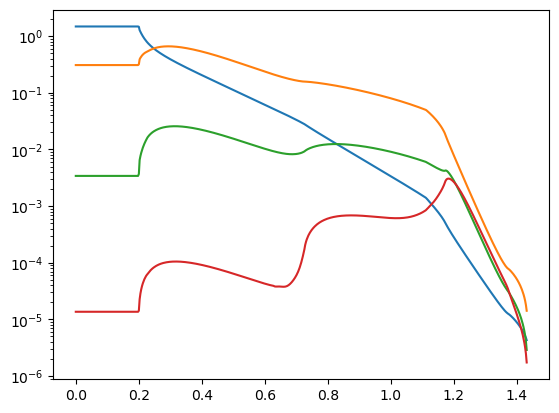

In [148]:
plt.semilogy(x, solution_values.T)